# Clase 2 · Parte 3 — Clustering geoespacial: K-means por dentro, coordenadas sí o no, y otros algoritmos

En la Parte 1 corrimos un K-means sobre los hexágonos H3 con cuatro variables de terreno (cota, pendiente, aporte, HAND) y le pusimos nombre a los grupos. Acá abrimos la caja:

1. **K-means paso a paso**, implementado a mano en NumPy: inicialización k-means++, asignación, actualización de centroides, convergencia e inercia. Por qué escalar, cómo elegir k, estabilidad entre semillas y cómo volver a unidades reales.
2. **Con o sin coordenadas:** qué pasa si sumamos x/y del hexágono como variables, y con qué peso.
3. **Otros algoritmos con foco geo:** DBSCAN/HDBSCAN, regionalización con contigüidad, mezcla gaussiana, y autocorrelación espacial (Moran, LISA) como complemento.

| algoritmo | en este notebook |
|---|---|
| K-means (a mano y sklearn) | **se corre** |
| K-means + coordenadas con peso variable | **se corre** |
| DBSCAN y HDBSCAN (haversine) sobre barrios RENABAP | **se corre** |
| Aglomerativo (Ward) con conectividad de vecinos H3 | **se corre** |
| Gaussian Mixture (GMM) | **se corre** |
| Moran's I global y LISA (esda / libpysal) | **se corre** |
| SKATER, max-p, REDCAP (spopt / PySAL) | **solo se menciona** (código de referencia comentado) |

**Requisito:** haber corrido las Partes 1 y 2 (lee de la carpeta de Drive `MyDrive/datos_clase2_publico`).

In [1]:
import importlib, subprocess, sys
faltan = [p for p, m in [("h3","h3"),("geopandas","geopandas"),("scikit-learn","sklearn"),("pyarrow","pyarrow"),
                         ("esda","esda"),("libpysal","libpysal")] if importlib.util.find_spec(m) is None]
if faltan: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltan])
import os, warnings, time
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import h3
from scipy import sparse
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, HDBSCAN, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
warnings.filterwarnings("ignore")

# Google Drive: cada notebook corre en una sesión de Colab distinta, así que TODO lo que se
# comparte entre notebooks vive en esta carpeta de Drive (no en el disco local de la sesión).
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/datos_clase2_publico"   # misma ruta en 01, 02, 03 y 04
os.makedirs(DRIVE_DIR, exist_ok=True)
DATA_DIR = DRIVE_DIR

CRS_METRICO = "EPSG:32720"
K = 4
SEMILLA = 42
VARS = ["cota_media", "pendiente_media", "aporte_log_max", "hand_mediana"]
CELDA_KM2 = 30 * 30 / 1e6     # píxel del DEM de la Parte 1

ruta = os.path.join(DATA_DIR, "hexes_terreno_renabap_mapbiomas.parquet")   # lo escribe el 02
if not os.path.exists(ruta):
    ruta = os.path.join(DATA_DIR, "hexes_terreno.parquet")                     # lo escribe el 01
    print("No está el parquet del 02: sigo con el del 01 (sin familias).")
hexes = gpd.read_parquet(ruta).reset_index(drop=True)
hexes_m = hexes.to_crs(CRS_METRICO)
print(len(hexes), "hexágonos leídos de", ruta)

Mounted at /content/drive
4562 hexágonos leídos de /content/drive/MyDrive/datos_clase2_publico/hexes_terreno_renabap_mapbiomas.parquet


## 1. K-means paso a paso

### 1.1 Por qué escalar (y por qué el log de la acumulación)

K-means mide distancias euclídeas. Si una variable tiene números grandes, domina la distancia. Miremos las escalas:

- la cota va de ~8 a ~110 m;
- la pendiente es del orden de 0,01–0,1 m/m;
- la acumulación cruda, en **celdas**, va de una a cientos de miles, con una cola larguísima: pocos píxeles (los cauces) tienen valores enormes.

Por eso usamos el **log** de la acumulación (en la Parte 1, `aporte_log_max` = log10 del área de aporte máxima en km²) y después **estandarizamos** todo (media 0, desvío 1).

,mean,std,min,50%,max
cota_media,28.566,26.751,8.5,15.005,111.735
pendiente_media,0.022,0.015,0.0,0.019,0.115
acumulacion_celdas_max,13105.015,43236.569,39.0,1747.000,566767.000
hand_mediana,5.205,8.037,0.0,1.624,61.615


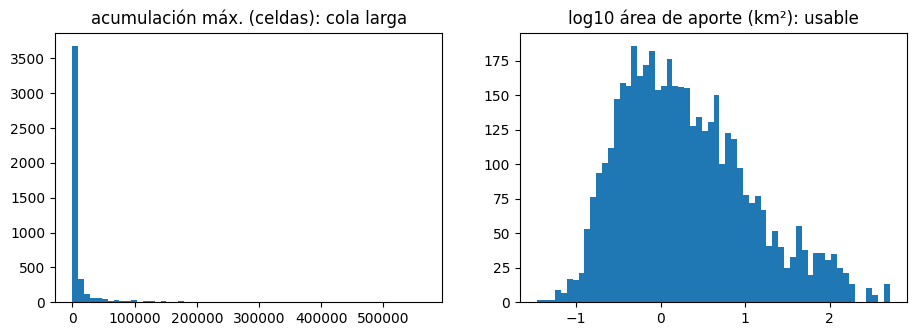

In [2]:
acc_celdas_max = 10 ** hexes["aporte_log_max"] / CELDA_KM2      # volvemos a "celdas" para mostrar la escala cruda
crudo = hexes[["cota_media", "pendiente_media"]].assign(acumulacion_celdas_max=acc_celdas_max, hand_mediana=hexes.hand_mediana)
display(crudo.describe().T[["mean", "std", "min", "50%", "max"]].round(3))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].hist(acc_celdas_max, bins=60); axs[0].set_title("acumulación máx. (celdas): cola larga")
axs[1].hist(hexes.aporte_log_max, bins=60); axs[1].set_title("log10 área de aporte (km²): usable")
plt.show()

In [3]:
# K-means sobre variables crudas (acumulación en celdas, sin escalar) vs nuestro esquema (log + escalado)
X_crudo = crudo.values
X = StandardScaler().fit_transform(hexes[VARS])
lab_crudo = KMeans(K, n_init=10, random_state=SEMILLA).fit_predict(X_crudo)
lab_ok = KMeans(K, n_init=10, random_state=SEMILLA).fit_predict(X)
print("ARI crudo vs escalado:", round(adjusted_rand_score(lab_crudo, lab_ok), 3))
print("\nMedias por grupo en la corrida CRUDA (fijate qué variable separa los grupos):")
display(crudo.groupby(lab_crudo).mean().round(3).assign(n=pd.Series(lab_crudo).value_counts().sort_index()))

ARI crudo vs escalado: 0.04

Medias por grupo en la corrida CRUDA (fijate qué variable separa los grupos):


,cota_media,pendiente_media,acumulacion_celdas_max,hand_mediana,n
0,29.501,0.022,3887.303,5.493,4177
1,11.835,0.024,435413.036,1.521,28
2,19.262,0.027,148195.676,2.648,102
3,18.805,0.021,63687.404,1.921,255


### 1.2 El algoritmo, a mano

1. **Inicialización k-means++.** El primer centroide es un hexágono al azar. Cada centroide siguiente se elige al azar con probabilidad proporcional a **d²** (distancia al cuadrado al centroide más cercano ya elegido). Así los centroides arrancan separados.
2. **Asignación.** Cada hexágono va al centroide más cercano.
3. **Actualización.** Cada centroide pasa a ser la **media** de sus hexágonos.
4. **Repetir 2–3** hasta que los centroides casi no se muevan (o ninguna asignación cambie).

La **inercia** es la suma de distancias² de cada hex a su centroide. Cada paso 2 y cada paso 3 la bajan o la dejan igual, así que el algoritmo converge. Pero converge a un **mínimo local**: depende del arranque. Por eso sklearn corre varias inicializaciones (`n_init`) y se queda con la de menor inercia.

In [4]:
def kmeanspp_init(X, k, rng):
    centros = [X[rng.integers(len(X))]]
    for _ in range(1, k):
        d2 = np.min(((X[:, None, :] - np.array(centros)[None]) ** 2).sum(-1), axis=1)
        centros.append(X[rng.choice(len(X), p=d2 / d2.sum())])
    return np.array(centros)

def kmeans_a_mano(X, k, semilla=0, max_iter=100, tol=1e-6, init="k-means++"):
    rng = np.random.default_rng(semilla)
    C = kmeanspp_init(X, k, rng) if init == "k-means++" else X[rng.choice(len(X), k, replace=False)]
    historia = []
    for it in range(max_iter):
        d2 = ((X[:, None, :] - C[None]) ** 2).sum(-1)           # (n, k) distancias²
        lab = d2.argmin(1)                                      # asignación
        inercia = d2[np.arange(len(X)), lab].sum()
        historia.append((C.copy(), lab.copy(), inercia))
        C_nuevo = np.array([X[lab == j].mean(0) if np.any(lab == j) else C[j] for j in range(k)])  # actualización
        mov = np.sqrt(((C_nuevo - C) ** 2).sum(1)).max()
        C = C_nuevo
        if mov < tol: break
    return lab, C, historia

lab_mano, C_mano, hist = kmeans_a_mano(X, K, semilla=SEMILLA)
print(f"convergió en {len(hist)} iteraciones · inercia final {hist[-1][2]:.1f}")
km = KMeans(K, n_init=20, random_state=SEMILLA).fit(X)
print(f"sklearn (n_init=20): inercia {km.inertia_:.1f} · ARI a mano vs sklearn: {adjusted_rand_score(lab_mano, km.labels_):.3f}")

convergió en 23 iteraciones · inercia final 6128.0
sklearn (n_init=20): inercia 6128.0 · ARI a mano vs sklearn: 1.000


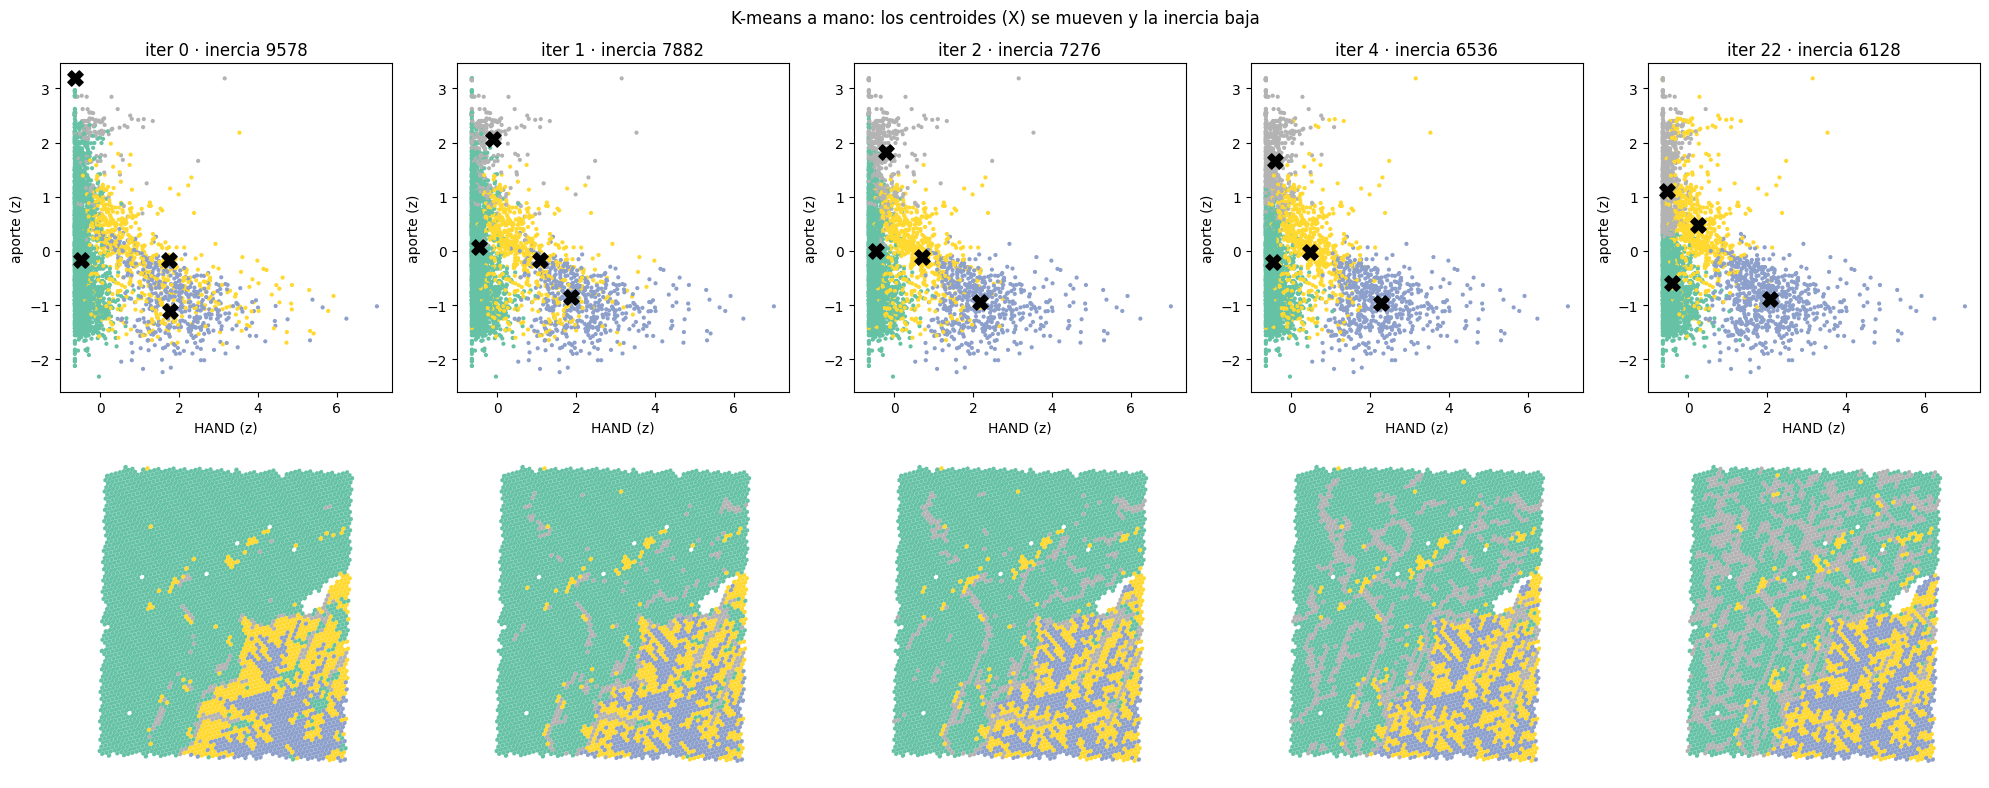

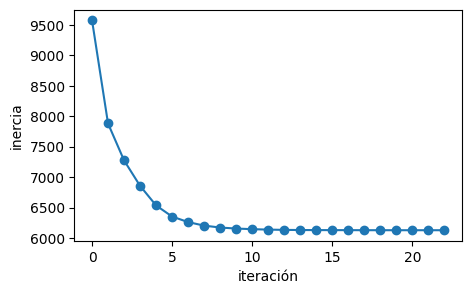

In [5]:
# Visual de las iteraciones en el plano (HAND, aporte) escalados + mapa
i_hand, i_ap = VARS.index("hand_mediana"), VARS.index("aporte_log_max")
mostrar = sorted(set([0, 1, 2, min(4, len(hist) - 1), len(hist) - 1]))
fig, axs = plt.subplots(2, len(mostrar), figsize=(4 * len(mostrar), 8))
for col, it in enumerate(mostrar):
    Cit, labit, inerit = hist[it]
    ax = axs[0, col]
    ax.scatter(X[:, i_hand], X[:, i_ap], c=labit, cmap="Set2", s=4)
    ax.scatter(Cit[:, i_hand], Cit[:, i_ap], c="k", marker="X", s=120)
    ax.set_title(f"iter {it} · inercia {inerit:.0f}"); ax.set_xlabel("HAND (z)"); ax.set_ylabel("aporte (z)")
    hexes_m.plot(ax=axs[1, col], color=plt.cm.Set2(labit / (K - 1)), edgecolor="none"); axs[1, col].set_axis_off()
plt.suptitle("K-means a mano: los centroides (X) se mueven y la inercia baja"); plt.tight_layout(); plt.show()
plt.figure(figsize=(5, 3)); plt.plot([h[2] for h in hist], "o-"); plt.xlabel("iteración"); plt.ylabel("inercia"); plt.show()

### 1.3 Cómo elegir k: codo y silueta

- **Codo:** la inercia siempre baja al subir k. Se busca dónde deja de bajar mucho.
- **Silueta:** para cada hex, `(b − a) / max(a, b)`, con *a* = distancia media a su grupo y *b* = distancia media al grupo vecino más cercano. Va de −1 a 1; más alto = grupos más separados.

Ninguno decide solo. El criterio final es que el mapa se pueda leer y que el grupo "bajo y drena" aparezca.

,inercia,silueta
k,,
2,9998.115,0.512
3,7478.461,0.361
4,6128.045,0.359
5,5207.118,0.368
6,4474.934,0.350
7,3905.626,0.334
8,3506.125,0.331


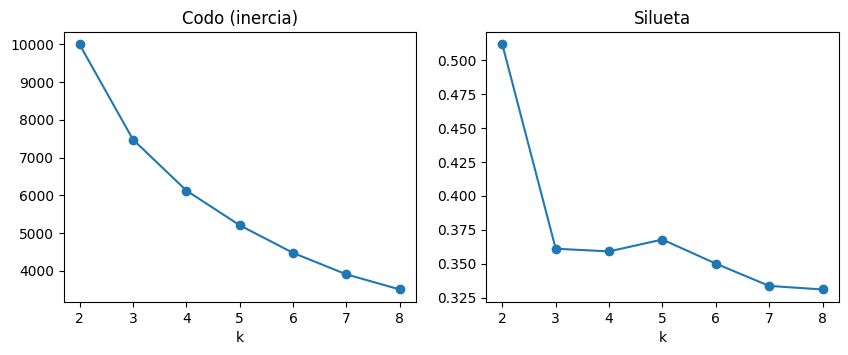

In [6]:
filas = []
for k in range(2, 9):
    m = KMeans(k, n_init=10, random_state=SEMILLA).fit(X)
    filas.append({"k": k, "inercia": m.inertia_, "silueta": silhouette_score(X, m.labels_)})
tabla_k = pd.DataFrame(filas).set_index("k")
display(tabla_k.round(3))
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
tabla_k.inercia.plot(ax=axs[0], marker="o", title="Codo (inercia)"); tabla_k.silueta.plot(ax=axs[1], marker="o", title="Silueta")
plt.show()

### 1.4 Estabilidad entre semillas

Corremos K-means con **una sola** inicialización (`n_init=1`) y 20 semillas distintas. ¿Cuánto varía la inercia? ¿Cuánto se parecen las soluciones a la mejor (ARI)? El ARI no depende del número que recibe cada grupo, solo de qué hexágonos van juntos.

In [7]:
res = []
for s in range(20):
    m = KMeans(K, n_init=1, random_state=s).fit(X)
    res.append((s, m.inertia_, m.labels_))
mejor = min(res, key=lambda r: r[1])
estab = pd.DataFrame({"semilla": [r[0] for r in res], "inercia": [r[1] for r in res],
                      "ARI_vs_mejor": [adjusted_rand_score(mejor[2], r[2]) for r in res]})
display(estab.describe().loc[["mean", "min", "max"]].round(3))
print("semillas con ARI < 0.9 respecto de la mejor:", (estab.ARI_vs_mejor < 0.9).sum(), "de 20")

,semilla,inercia,ARI_vs_mejor
mean,9.5,6128.094,0.997
min,0.0,6128.032,0.985
max,19.0,6128.395,1.000


semillas con ARI < 0.9 respecto de la mejor: 0 de 20


### 1.5 Volver a unidades reales

Los centroides de sklearn están en **unidades escaladas** (z). Para leerlos, `scaler.inverse_transform(km.cluster_centers_)`. Como el escalado es lineal y el centroide es la media, da prácticamente lo mismo que la media de cada grupo en variables originales (sklearn reasigna una última vez después de actualizar los centroides, así que puede haber diferencias de centésimas). Lo verificamos y nombramos con la regla de la Parte 1: **HAND bajo y aporte alto = riesgo**.

In [8]:
scaler = StandardScaler().fit(hexes[VARS])
km = KMeans(K, n_init=20, random_state=SEMILLA).fit(scaler.transform(hexes[VARS]))
cent_inv = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=VARS)
cent_med = hexes[VARS].groupby(km.labels_).mean()
print("máx. diferencia |inverse_transform − media por grupo|:", float((cent_inv - cent_med).abs().max().max()))
cent_z = pd.DataFrame(km.cluster_centers_, columns=VARS)
cent_inv["puntaje_riesgo"] = (cent_z.aporte_log_max - cent_z.hand_mediana).round(2)
cent_inv["n_hex"] = np.bincount(km.labels_)
GR = int(cent_inv.puntaje_riesgo.idxmax())
hexes["km"] = km.labels_
display(cent_inv.round(3).sort_values("puntaje_riesgo", ascending=False))
print("grupo de riesgo:", GR)

máx. diferencia |inverse_transform − media por grupo|: 0.026024784587981742


,cota_media,pendiente_media,aporte_log_max,hand_mediana,puntaje_riesgo,n_hex
0,14.223,0.015,1.142,0.921,1.65,1298
2,48.768,0.040,0.654,7.101,0.23,634
1,14.918,0.016,-0.146,1.801,-0.17,1967
3,77.871,0.035,-0.368,21.887,-2.96,663


grupo de riesgo: 0


## 2. ¿Con o sin coordenadas?

Si sumamos la posición del hexágono (x, y del centroide en UTM, escaladas) como variables, K-means empieza a agrupar también **por cercanía**. Con un peso `w` multiplicamos x e y escalados: `w = 0` es solo terreno; con `w` grande manda la geografía y los grupos se vuelven "regiones".

Métricas para comparar:
- **ARI vs solo-variables:** cuánto cambia la partición.
- **Silueta en el espacio de variables** (sin coordenadas): qué tan homogéneo es cada grupo *en terreno*.
- **Compacidad espacial:** cantidad de **componentes conexas** por grupo según la vecindad H3 (un grupo contiguo = 1 componente) y **% de pares vecinos en el mismo grupo**.

In [9]:
# Grafo de vecindad H3 (vecinos directos, anillo 1)
idx = {c: i for i, c in enumerate(hexes.h3)}
filas_, cols_ = [], []
for c, i in idx.items():
    for v in h3.grid_disk(c, 1):
        j = idx.get(v)
        if j is not None and j != i: filas_.append(i); cols_.append(j)
A = sparse.csr_matrix((np.ones(len(filas_)), (filas_, cols_)), shape=(len(idx), len(idx)))
print(f"{A.nnz // 2:,} pares de vecinos · vecinos medios por hex: {A.nnz / len(idx):.2f}")

def compacidad(lab):
    comp = 0
    for g in np.unique(lab):
        m = np.where(lab == g)[0]
        comp += connected_components(A[m][:, m], directed=False)[0]
    r, c = A.nonzero()
    return comp, float((lab[r] == lab[c]).mean())

xy = np.c_[hexes_m.geometry.centroid.x, hexes_m.geometry.centroid.y]
XY = StandardScaler().fit_transform(xy)
base = KMeans(K, n_init=20, random_state=SEMILLA).fit_predict(X)
filas = []; etiquetas = {}
for w in [0, 0.5, 1, 2, 4]:
    lab = KMeans(K, n_init=20, random_state=SEMILLA).fit_predict(np.c_[X, w * XY])
    etiquetas[w] = lab
    comp, mismo = compacidad(lab)
    filas.append({"peso_coord": w, "ARI_vs_solo_variables": adjusted_rand_score(base, lab),
                  "silueta_en_variables": silhouette_score(X, lab), "componentes_conexas": comp,
                  "pct_vecinos_mismo_grupo": 100 * mismo})
comp_coord = pd.DataFrame(filas).set_index("peso_coord").round(3)
comp_coord

13,338 pares de vecinos · vecinos medios por hex: 5.85


,ARI_vs_solo_variables,silueta_en_variables,componentes_conexas,pct_vecinos_mismo_grupo
peso_coord,,,,
0.0,1.000,0.359,209,61.156
0.5,0.954,0.357,194,61.613
1.0,0.404,0.141,78,79.697
2.0,0.208,0.057,16,96.596
4.0,0.191,0.044,6,97.286


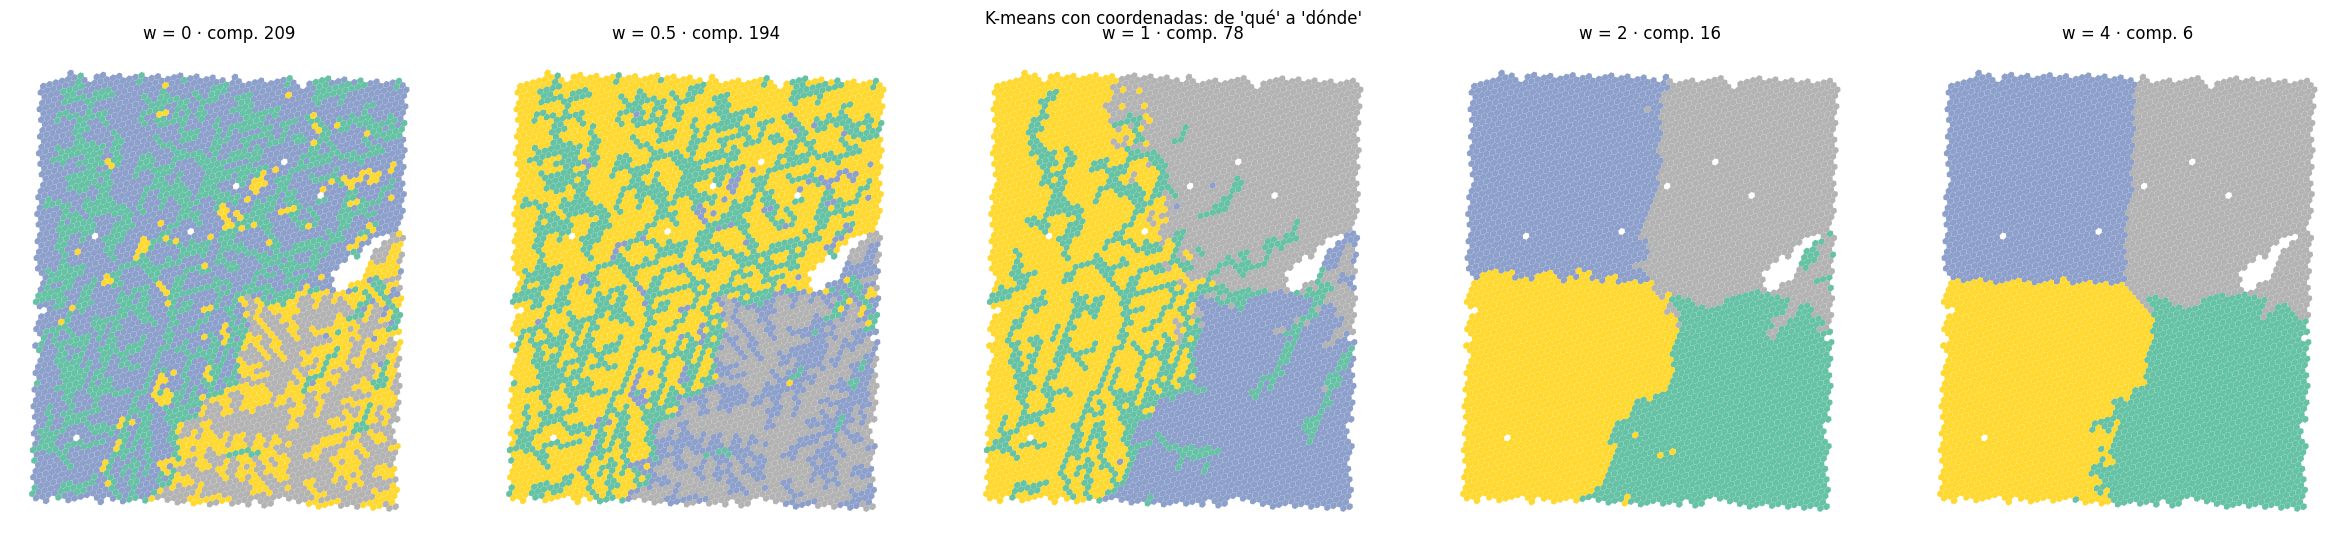

In [10]:
fig, axs = plt.subplots(1, 5, figsize=(24, 5.5))
for ax, (w, lab) in zip(axs, etiquetas.items()):
    hexes_m.plot(ax=ax, color=plt.cm.Set2(lab / (K - 1)), edgecolor="none"); ax.set_axis_off()
    ax.set_title(f"w = {w} · comp. {comp_coord.loc[w, 'componentes_conexas']:.0f}")
plt.suptitle("K-means con coordenadas: de 'qué' a 'dónde'"); plt.tight_layout(); plt.show()

Ojo: los colores no se corresponden entre paneles (el número de grupo es arbitrario en cada corrida); por eso comparamos con ARI.

**Para discutir.** Las coordenadas fuerzan grupos contiguos (regionalización), pero mezclan **dónde** con **qué**: un arroyo bajo en medio de la meseta entrerriana puede terminar en el grupo "meseta" porque está ahí, no porque sea igual (comparalo en los mapas de w = 0 y w = 2). Para riesgo conviene **agrupar solo por variables** y después **mirar el patrón espacial** (mapa, Moran, LISA). Las coordenadas sirven cuando el objetivo es armar zonas de gestión contiguas.

## 3. Otros algoritmos con foco geo

### 3.1 DBSCAN y HDBSCAN: densidad, para puntos (barrios RENABAP)

DBSCAN agrupa puntos que tienen al menos `min_samples` vecinos dentro de un radio `eps`; lo que queda aislado es **ruido** (−1). No hay que fijar k. Con coordenadas lat/lon se usa la métrica **haversine** (distancia sobre la esfera), en **radianes**: `eps = metros / 6.371.000`.

HDBSCAN es la versión jerárquica: prueba todos los radios y se queda con los grupos más estables. Solo pide `min_cluster_size`.

Acá lo usamos para encontrar **aglomeraciones de barrios populares** y después preguntarle a la HAND (Parte 2) qué tan bajas son.

In [11]:
# Barrios de la ventana con su HAND: los guardó el 02 en Drive (con geometría)
ruta_b = os.path.join(DATA_DIR, "barrios_ventana_hand.parquet")
if not os.path.exists(ruta_b):
    raise FileNotFoundError(f"Falta {ruta_b}: corré el notebook 02 hasta la última celda.")
barrios = gpd.read_parquet(ruta_b).reset_index(drop=True)
cen = barrios.to_crs(CRS_METRICO).geometry.centroid.to_crs("EPSG:4326")
coords_rad = np.radians(np.c_[cen.y, cen.x])     # haversine pide (lat, lon) en radianes
R = 6_371_000
db = DBSCAN(eps=1000 / R, min_samples=3, metric="haversine", algorithm="ball_tree").fit(coords_rad)
hdb = HDBSCAN(min_cluster_size=4, metric="haversine", copy=True).fit(coords_rad)
barrios["dbscan"], barrios["hdbscan"] = db.labels_, hdb.labels_
for nombre in ["dbscan", "hdbscan"]:
    lab = barrios[nombre]
    print(f"{nombre}: {lab.max() + 1} aglomeraciones · {(lab == -1).sum()} barrios como ruido de {len(lab)}")
resumen = barrios[barrios.dbscan >= 0].groupby("dbscan").agg(
    barrios=("id_renabap", "size"), familias=("cantidad_familias_aproximada", "sum"),
    hand_mediana=("hand_mediana_barrio", "median"), frac_bajo_2m=("frac_lt2", "mean"),
    localidad=("localidad", lambda s: s.mode().iat[0])).sort_values("familias", ascending=False)
resumen.round(2)


dbscan: 17 aglomeraciones · 51 barrios como ruido de 169
hdbscan: 10 aglomeraciones · 41 barrios como ruido de 169


,barrios,familias,hand_mediana,frac_bajo_2m,localidad
dbscan,,,,,
8,18,5000,0.83,0.63,Santa Fe
9,8,4716,2.49,0.41,Santa Fe
3,14,3315,12.20,0.16,Paraná
10,9,2854,1.39,0.53,Santa Fe
4,13,1843,7.91,0.20,Paraná
1,14,1261,11.44,0.10,Paraná
11,7,914,0.87,0.72,Santa Fe
0,3,787,14.01,0.00,Paraná
6,3,493,28.63,0.00,Paraná


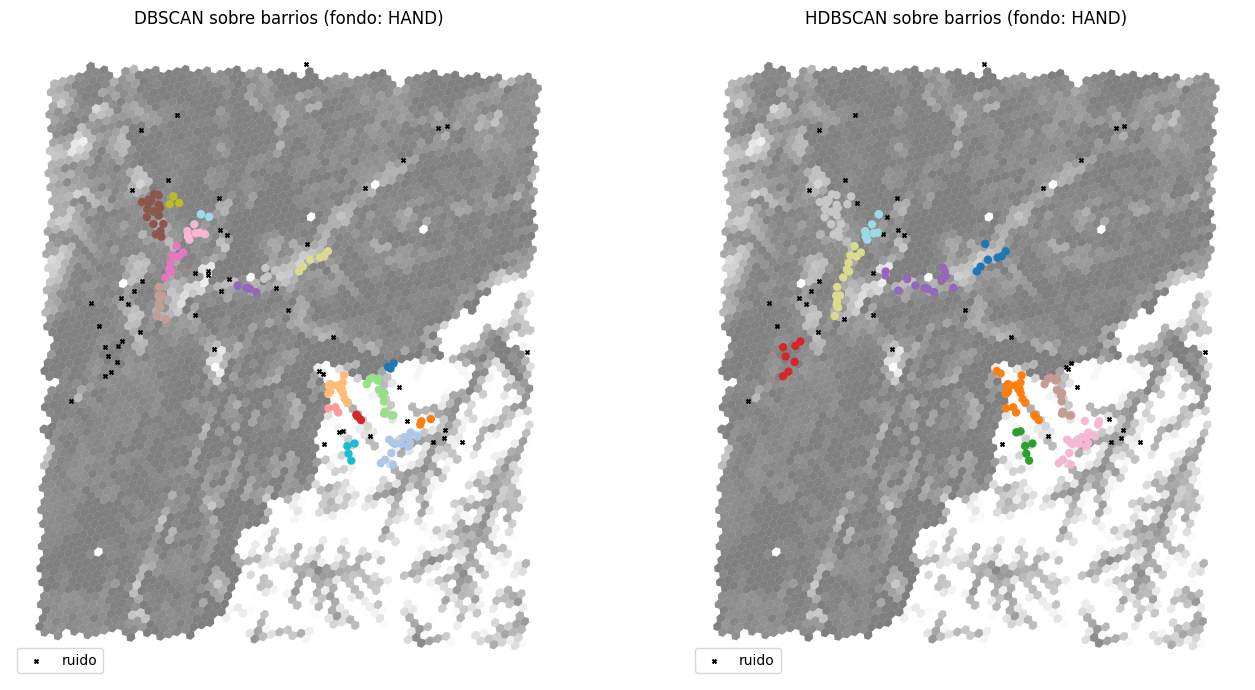

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
for ax, nombre in zip(axs, ["dbscan", "hdbscan"]):
    hexes_m.plot(ax=ax, column="hand_mediana", cmap="Greys_r", vmax=15, alpha=0.5)
    b = barrios.to_crs(CRS_METRICO); c = b.geometry.centroid
    ruido = b[nombre] == -1
    ax.scatter(c[ruido].x, c[ruido].y, c="k", s=8, marker="x", label="ruido")
    ax.scatter(c[~ruido].x, c[~ruido].y, c=b.loc[~ruido, nombre], cmap="tab20", s=25)
    ax.set_title(f"{nombre.upper()} sobre barrios (fondo: HAND)"); ax.set_axis_off(); ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

### 3.2 Regionalización con contigüidad: aglomerativo (Ward) con vecinos H3

El aglomerativo arranca con cada hex como grupo y va uniendo de a pares el que menos aumenta la varianza (Ward). Si le pasamos una **matriz de conectividad**, solo puede unir grupos **vecinos**. Resultado: regiones contiguas armadas **solo con variables de terreno**, sin meter las coordenadas como variable.

Es la idea de los métodos de regionalización de PySAL/`spopt` (**solo mencionados, no se corren acá**):
- **SKATER:** árbol de expansión mínima sobre el grafo de vecinos, que se corta en k regiones.
- **REDCAP:** familia de métodos jerárquicos con restricción de contigüidad.
- **max-p:** elige cuántas regiones armar, con un umbral mínimo por región (por ejemplo, al menos N familias).

```python
# Referencia (no se ejecuta): pip install spopt
# from spopt.region import Skater
# w = libpysal.weights.W(vecinos)   # el mismo grafo H3 de abajo
# m = Skater(hexes, w, VARS, n_clusters=K); m.solve(); hexes["skater"] = m.labels_
```

aglomerativo con contigüidad en 0.3 s · componentes conexas 4 · vecinos mismo grupo 90.6 % · ARI vs K-means 0.352 · silueta en variables 0.149
aglomerativo SIN contigüidad: componentes 268 · ARI vs K-means 0.669


,cota_media,pendiente_media,aporte_log_max,hand_mediana,n
agg_contig,,,,,
0,47.50,0.05,0.26,16.35,352
1,12.49,0.02,0.77,1.23,944
2,73.81,0.03,0.12,14.46,899
3,14.98,0.02,0.19,1.62,2367


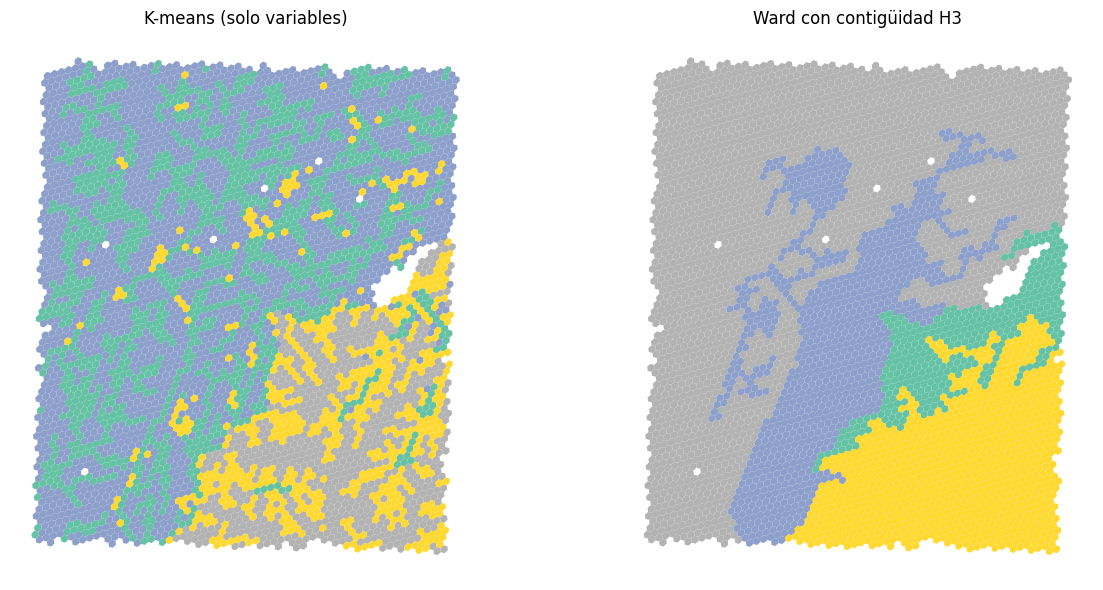

In [13]:
t0 = time.time()
agg = AgglomerativeClustering(n_clusters=K, linkage="ward", connectivity=A).fit(X)
hexes["agg_contig"] = agg.labels_
comp, mismo = compacidad(agg.labels_)
print(f"aglomerativo con contigüidad en {time.time()-t0:.1f} s · componentes conexas {comp} · "
      f"vecinos mismo grupo {100*mismo:.1f} % · ARI vs K-means {adjusted_rand_score(hexes.km, agg.labels_):.3f} · "
      f"silueta en variables {silhouette_score(X, agg.labels_):.3f}")
agg_libre = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
print(f"aglomerativo SIN contigüidad: componentes {compacidad(agg_libre)[0]} · ARI vs K-means {adjusted_rand_score(hexes.km, agg_libre):.3f}")
display(hexes.groupby("agg_contig")[VARS].mean().round(2).assign(n=hexes.agg_contig.value_counts().sort_index()))
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
hexes_m.plot(ax=axs[0], color=plt.cm.Set2(hexes.km / (K - 1)), edgecolor="none"); axs[0].set_title("K-means (solo variables)")
hexes_m.plot(ax=axs[1], color=plt.cm.Set2(hexes.agg_contig / (K - 1)), edgecolor="none"); axs[1].set_title("Ward con contigüidad H3")
for a in axs: a.set_axis_off()
plt.tight_layout(); plt.show()

### 3.3 Mezcla gaussiana (GMM): grupos elípticos y asignación "blanda"

K-means asume grupos esféricos de tamaño parecido y asigna cada hex a un solo grupo. Una **mezcla gaussiana** modela cada grupo como una normal con su propia covarianza (grupos elípticos) y da, para cada hex, la **probabilidad** de pertenecer a cada grupo. Los hexágonos con probabilidad máxima baja son los **ambiguos**, los que están en la frontera entre dos tipos de terreno. k se puede elegir con el **BIC** (más bajo = mejor).

BIC por k: {2: 27214, 3: 24877, 4: 23569, 5: 22810, 6: 22147, 7: 21558, 8: 21513}
ARI GMM vs K-means: 0.295 · hex ambiguos (p máx < 0,6): 173


,cota_media,pendiente_media,aporte_log_max,hand_mediana,n
gmm,,,,,
0,43.20,0.05,0.68,17.05,305
1,12.14,0.01,0.49,0.88,2051
2,75.40,0.03,0.01,14.73,923
3,17.65,0.02,0.12,2.46,1283


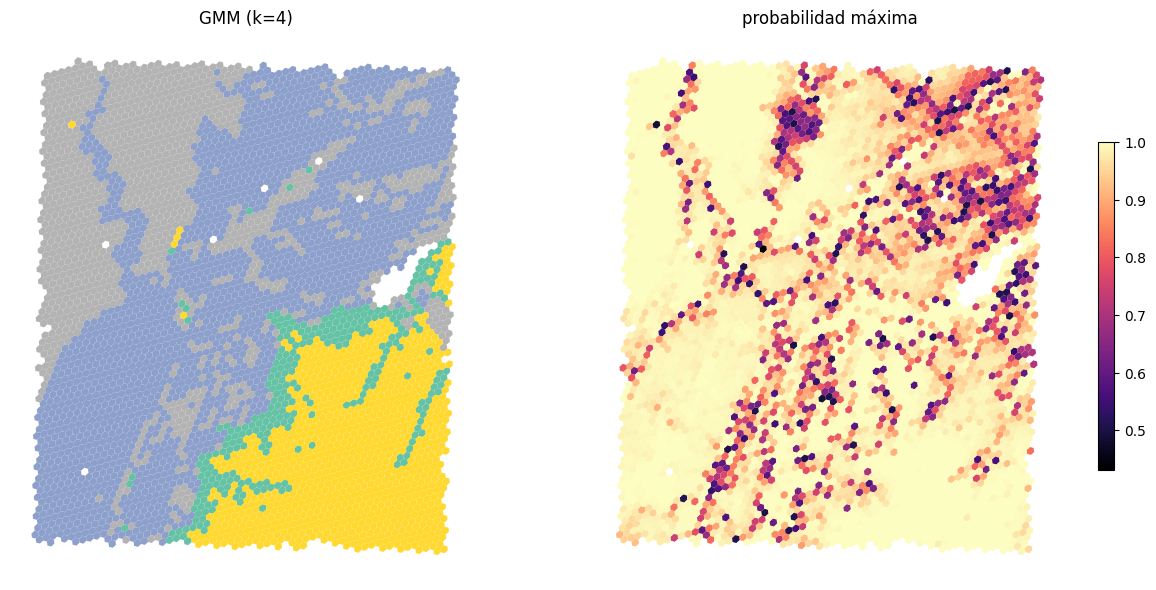

In [14]:
bic = {k: GaussianMixture(k, covariance_type="full", random_state=SEMILLA, n_init=3).fit(X).bic(X) for k in range(2, 9)}
print("BIC por k:", {k: round(v) for k, v in bic.items()})
gmm = GaussianMixture(K, covariance_type="full", random_state=SEMILLA, n_init=3).fit(X)
P = gmm.predict_proba(X)
hexes["gmm"], hexes["gmm_pmax"] = P.argmax(1), P.max(1)
print(f"ARI GMM vs K-means: {adjusted_rand_score(hexes.km, hexes.gmm):.3f} · hex ambiguos (p máx < 0,6): {(hexes.gmm_pmax < 0.6).sum()}")
display(hexes.groupby("gmm")[VARS].mean().round(2).assign(n=hexes.gmm.value_counts().sort_index()))
fig, axs = plt.subplots(1, 2, figsize=(13, 6))
hexes_m.plot(ax=axs[0], color=plt.cm.Set2(hexes.gmm / (K - 1)), edgecolor="none"); axs[0].set_title("GMM (k=4)")
hexes_m.plot(ax=axs[1], column=hexes.gmm_pmax, cmap="magma", legend=True, legend_kwds={"shrink": 0.6}); axs[1].set_title("probabilidad máxima")
for a in axs: a.set_axis_off()
plt.tight_layout(); plt.show()

### 3.4 Complemento: autocorrelación espacial (Moran's I y LISA)

No es clustering, pero responde la pregunta que dejamos abierta en la sección 2: agrupamos **solo por variables**, ¿hay patrón espacial?

- **Moran's I global:** ¿los hexágonos parecidos están cerca entre sí? Va de ~−1 a 1; 0 = sin patrón. El p-valor sale de permutaciones al azar.
- **LISA (Moran local):** para cada hex, si él y sus vecinos son altos (**HH**, *hot spot*), bajos (**LL**, *cold spot*), o mezclados (HL, LH).

Variable: el **puntaje de riesgo por hex**, `z(aporte) − z(HAND)`, la misma regla con la que nombramos el grupo de riesgo. Los pesos espaciales salen del mismo grafo de vecinos H3, estandarizados por fila.

In [15]:
import libpysal, esda
vecinos = {i: list(A.indices[A.indptr[i]:A.indptr[i + 1]]) for i in range(A.shape[0])}
W = libpysal.weights.W(vecinos, silence_warnings=True); W.transform = "r"
z = lambda s: (s - s.mean()) / s.std()
hexes["puntaje_riesgo"] = z(hexes.aporte_log_max) - z(hexes.hand_mediana)
np.random.seed(SEMILLA)
for col in ["puntaje_riesgo", "hand_mediana", "pendiente_media"]:
    mi = esda.Moran(hexes[col].values, W, permutations=999)
    print(f"Moran's I {col:16s}: {mi.I:.3f} (p perm = {mi.p_sim:.3f})")
lisa = esda.Moran_Local(hexes.puntaje_riesgo.values, W, permutations=999, seed=SEMILLA)
sig = lisa.p_sim < 0.05
cuad = {1: "HH (hot spot)", 2: "LH", 3: "LL (cold spot)", 4: "HL"}
hexes["lisa"] = np.where(sig, pd.Series(lisa.q).map(cuad), "no significativo")
tab = hexes.groupby("lisa").agg(hex=("h3", "size"))
if "familias" in hexes: tab["familias_aprox"] = hexes.groupby("lisa").familias.sum().round(0)
display(tab)
display(pd.crosstab(hexes.lisa, hexes.km, margins=True).rename(columns={GR: f"{GR} (riesgo)"}))

Moran's I puntaje_riesgo  : 0.539 (p perm = 0.001)
Moran's I hand_mediana    : 0.764 (p perm = 0.001)
Moran's I pendiente_media : 0.688 (p perm = 0.001)


,hex,familias_aprox
lisa,,
HH (hot spot),526,2331.0
HL,53,1325.0
LH,122,1105.0
LL (cold spot),611,5421.0
no significativo,3250,22166.0


km,0 (riesgo),1,2,3,All
lisa,,,,,
HH (hot spot),430,75,21,0,526
HL,1,1,51,0,53
LH,0,112,9,1,122
LL (cold spot),0,2,100,509,611
no significativo,867,1777,453,153,3250
All,1298,1967,634,663,4562


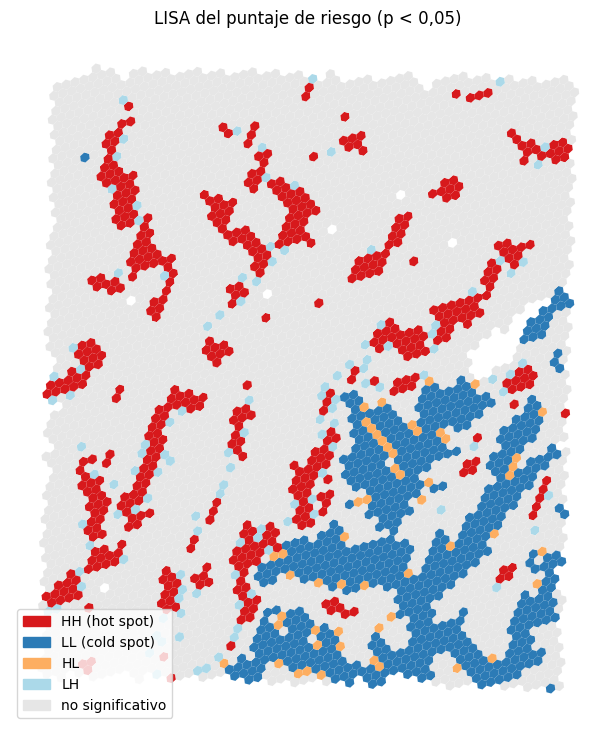

In [16]:
colores_lisa = {"HH (hot spot)": "#d7191c", "LL (cold spot)": "#2c7bb6", "HL": "#fdae61", "LH": "#abd9e9", "no significativo": "0.9"}
ax = hexes_m.plot(color=hexes.lisa.map(colores_lisa), edgecolor="none", figsize=(9, 9))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=v, label=k) for k, v in colores_lisa.items()], loc="lower left")
ax.set_axis_off(); ax.set_title("LISA del puntaje de riesgo (p < 0,05)"); plt.show()

---
## Ejercicios

**Ejercicio 1 — Inicialización.** Con `kmeans_a_mano`, compará `init="k-means++"` contra `init="random"` en 20 semillas: iteraciones hasta converger e inercia final. ¿Cuál es más estable?

In [17]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
filas = []
for init in ["k-means++", "random"]:
    for s in range(20):
        _, _, h_ = kmeans_a_mano(X, K, semilla=s, init=init)
        filas.append({"init": init, "iteraciones": len(h_), "inercia": h_[-1][2]})
display(pd.DataFrame(filas).groupby("init").agg(["mean", "min", "max"]).round(1))

iteraciones         inercia                
                 mean min max    mean     min     max
init                                                 
k-means++        38.2  16  76  6128.0  6128.0  6128.1
random           35.2  18  54  6128.0  6128.0  6128.0

**Ejercicio 2 — Sin escalar.** Corré K-means con las cuatro variables **sin** `StandardScaler` (pero con el log de la acumulación). ¿Qué variable define los grupos? Calculá el ARI contra la versión escalada.

In [18]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
lab_sin = KMeans(K, n_init=10, random_state=SEMILLA).fit_predict(hexes[VARS].values)
print("ARI sin escalar vs escalado:", round(adjusted_rand_score(lab_sin, hexes.km), 3))
display(hexes[VARS].groupby(lab_sin).agg(["mean", "std"]).round(3))
# La cota (desvío ~27 m) y la HAND (~8 m) dominan la distancia; la pendiente (~0,01) casi no cuenta.

ARI sin escalar vs escalado: 0.361


cota_media        pendiente_media        aporte_log_max        hand_mediana  \
        mean    std            mean    std           mean    std         mean   
0     14.456  4.000           0.017  0.013          0.367  0.757        1.591   
1     95.697  8.025           0.032  0.006         -0.235  0.463       19.935   
2     47.155  8.123           0.041  0.019          0.343  0.835       14.948   
3     71.419  7.239           0.030  0.008          0.148  0.663       13.714   

          
     std  
0  1.895  
1  7.914  
2  9.878  
3  9.510

**Ejercicio 3 — Elegir el peso de las coordenadas.** Buscá el `w` más chico para el que cada grupo tenga, en promedio, a lo sumo 10 componentes conexas. ¿Cuánto cae la silueta en variables respecto de `w = 0`?

In [19]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
filas = []
for w in [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6]:
    lab = KMeans(K, n_init=10, random_state=SEMILLA).fit_predict(np.c_[X, w * XY])
    filas.append({"w": w, "comp_por_grupo": compacidad(lab)[0] / K, "silueta_variables": silhouette_score(X, lab)})
t = pd.DataFrame(filas).set_index("w").round(3); display(t)
ok = t[t.comp_por_grupo <= 10]
print("w mínimo que cumple:", ok.index.min() if len(ok) else "ninguno en la grilla probada")

,comp_por_grupo,silueta_variables
w,,
0.00,52.50,0.359
0.25,51.25,0.359
0.50,48.25,0.357
0.75,44.50,0.354
1.00,20.00,0.145
1.50,5.50,0.061
2.00,4.00,0.057
3.00,2.50,0.054
4.00,1.50,0.044


w mínimo que cumple: 1.5


**Ejercicio 4 — Sensibilidad de DBSCAN.** Probá `eps` de 500 m, 1 km y 2 km (con `min_samples=3`). ¿Cuántas aglomeraciones y cuánto ruido? ¿Con qué radio aparece "una gran aglomeración por ciudad"?

In [20]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
for eps_m in [500, 1000, 2000]:
    lab = DBSCAN(eps=eps_m / R, min_samples=3, metric="haversine", algorithm="ball_tree").fit_predict(coords_rad)
    tam = pd.Series(lab[lab >= 0]).value_counts()
    print(f"eps {eps_m:>4} m: {lab.max()+1:2d} aglomeraciones · ruido {np.sum(lab == -1):3d} · "
          f"la más grande tiene {tam.max() if len(tam) else 0} barrios")

eps  500 m:  8 aglomeraciones · ruido 139 · la más grande tiene 9 barrios
eps 1000 m: 17 aglomeraciones · ruido  51 · la más grande tiene 18 barrios
eps 2000 m:  5 aglomeraciones · ruido  16 · la más grande tiene 69 barrios


**Ejercicio 5 — ¿Dónde duda el modelo?** Con la GMM, mapeá los hexágonos con probabilidad máxima < 0,6. ¿Entre qué grupos de K-means están? ¿Coinciden con bordes de barranca o con la planicie?

173 hex ambiguos


gmm,0,1,2,3
km,,,,
0,1,29,1,20
1,0,45,2,41
2,9,1,5,2
3,5,0,12,0


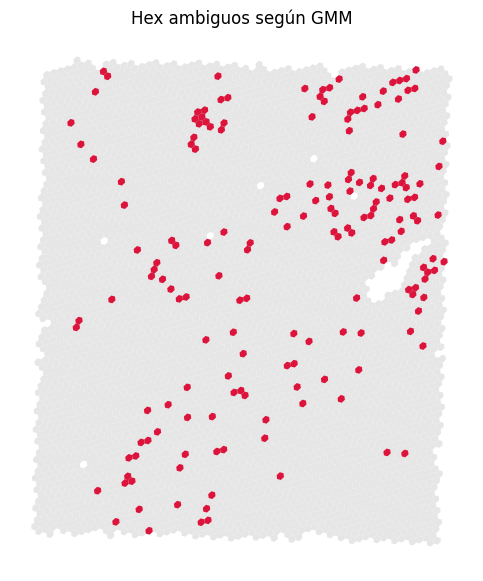

In [ ]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
amb = hexes[hexes.gmm_pmax < 0.6]
print(len(amb), "hex ambiguos")
display(pd.crosstab(amb.km, amb.gmm))
ax = hexes_m.plot(color="0.9", figsize=(7, 7)); hexes_m[hexes.gmm_pmax < 0.6].plot(ax=ax, color="crimson"); ax.set_axis_off()
ax.set_title("Hex ambiguos según GMM"); plt.show()

**Ejercicio 6 — Moran por variable.** ¿Qué variable tiene más autocorrelación espacial: `cota_media`, `pendiente_media`, `aporte_log_max` o `hand_mediana`? Explicalo con el terreno: ¿por qué el aporte, que dibuja líneas finas (cauces), tendría un I más bajo?

In [21]:
#@title Solución (abrila después de intentar) { display-mode: "form" }
for col in VARS:
    mi = esda.Moran(hexes[col].values, W, permutations=199)
    print(f"{col:16s} I = {mi.I:.3f} (p = {mi.p_sim:.3f})")
# Cota y HAND cambian suave en el espacio (planicie vs meseta); el aporte máximo salta de un hex con cauce
# a uno sin cauce, así que los vecinos se parecen menos.

cota_media       I = 0.982 (p = 0.005)
pendiente_media  I = 0.688 (p = 0.005)
aporte_log_max   I = 0.314 (p = 0.005)
hand_mediana     I = 0.764 (p = 0.005)


**Para la hoja:** agregá una línea a "qué todavía no se puede decir": ¿el grupo de riesgo depende del algoritmo? (Compará K-means, Ward con contigüidad y GMM.)